# Developing a Knowledge Based Agent

## Step 1: Identify the Task

The task is to navigate an autonomous trailer from a starting town to a destination town across a Kenyan road network. The agent must avoid blocked or closed roads and consider traffic.

**Goal**: Identify the lowest-cost valid route safely and efficiently using Uniform Cost Search (UCS) over inferred traffic conditions

## Step 2: Assemble Relevant Knowledge

The system needs to know:
- The weighted directed road graph connecting towns and their distances (in km)
- Maximum permitted trailer load (25 tons)
- Minimum traffic sensor confidence (0.5)
- Manually blocked road segments
- Live traffic conditions (current speed, free-flow speed, confidence and road closures) acquired via the **TomTom Geocoding, Routing and Traffic Flow APIs**.

In [15]:
import os
import requests
import heapq
from urllib.parse import quote

## Step 3: Define the vocabulary

- Predicates & Functions
  - Road(origin, destination, distance) (`self.graph_edges`)
  - Blocked(origin, destination) (`self.rules["blocked_routes"]`)
  - MaxLoad(tons) (`self.rules["max_load_weight tons"]`)
  - TrafficFact(route, current_speed, free_flow_speed, confidence, road_closure)
  - TrafficCondition(route, status)(`self.inferred_traffic`)
  - CostMultiplier(status, multiplier)(`self.rules["traffic_multipliers"]`)
    

- Constants:
  - Traffic States: clear, moderate, heavy, severe, closed, unknown

## Step 4: Encode Generatl knowledge about the domain

The knowledge base stores the road network, domain rules, traffic facts, representative road coordinates, and inferred traffic states.

In [16]:
class KnowledgeBase:
    """
    Stores the road network, domain rules and route information 
    used by the navigation agent.
    """

    def __init__(self):
        # Weighted directed graph from Practical Exercise 3
        self.graph_edges = {
            "Nairobi": {
                "Thika": 45.1,
                "Nyeri": 151,
                "Naivasha": 91,
                "Narok": 143
            },
            "Thika": {"Embu": 92.3},
            "Embu": {},
            "Nyeri": {"Nyahururu": 104},
            "Nyahururu": {"Nakuru": 63.3},
            "Naivasha": {"Nakuru": 71.1},
            "Nakuru": {
                "Eldoret": 156,
                "Kericho": 107
            },
            "Eldoret": {"Kisumu": 138},
            "Kericho": {"Kisumu": 84},
            "Narok": {"Kisii": 163},
            "Kisii": {"Kisumu": 114},
            "Kisumu": {}
        }

        # Rules and settings used by the agent
        self.rules = {
            "max_load_weight_tons": 25,
            "blocked_routes": [],
            "minimum_confidence": 0.5,
            "traffic_multipliers": {
                "clear": 1.0,
                "moderate": 1.3,
                "heavy": 1.7,
                "severe": 2.5
            }
        }

        # API observations and traffic labels inferred from them
        self.traffic_facts = {}
        self.inferred_traffic = {}
        self.edge_coordinates = {}

        
    def get_neighbours(self, current_node):
        """
        Finds valid neighboring nodes reachable from `current_node`
        that are not currently marked as blocked in `self.rules["blocked_routes"]`.
        """
        neighbours = self.graph_edges.get(current_node, {})
        valid_neighbours = {}

        for next_node, distance in neighbours.items():

            route = (current_node, next_node)

            # Exclude manually blocked routes
            if route in self.rules["blocked_routes"]:
                continue

            # Exclude routes inferred to be closed
            if self.inferred_traffic.get(route) == "closed":
                continue

            # Adjust cost according to inferred traffic conditions
            status = self.inferred_traffic.get(route, "unknown")

            # If traffic is unknown, use the neutral multiplier (1.0)
            multiplier = self.rules["traffic_multipliers"].get(status, 1.0)

            valid_neighbours[next_node] = distance * multiplier
        
        return valid_neighbours


    def check_rule(self, rule_key, value=None):
        """
        Evaluate a domain rule or fact in the knowledge base (e.g., payload capacity
        or route availability) for precondition checking during search.
        """

        if rule_key == "max_load_weight_tons":
            if value is None:
                return True
            return (
                isinstance(value, (int, float))
                and not isinstance(value, bool)
                and 0 <= value <= self.rules[rule_key]
            )

        return self.rules.get(rule_key)

    def add_blocked_route(self, node_a, node_b):
        """Mark a road segment as temporarily unvailable"""

        if node_b not in self.graph_edges.get(node_a, {}):
            print(f"No road connection exists: {node_a} -> {node_b}")
            return False

        route = (node_a, node_b)

        if route not in self.rules["blocked_routes"]:
            self.rules["blocked_routes"].append(route)
            print(f"Blocked road: {node_a} -> {node_b}")
            return True

        print("Road is already blocked.")
        return False

    def remove_blocked_route(self, node_a, node_b):
        """Restore a previously blocked road segment."""

        route = (node_a, node_b)

        if route in self.rules["blocked_routes"]:
            self.rules["blocked_routes"].remove(route)
            print(f"Restored road: {node_a} -> {node_b}")
            return True

        print("Road was not blocked.")
        return False

    def get_place_coordinates(self, place, api_key):
        """
        Retrieve the coordinates of a town using TomTom Geocoding.
        Returns (latitude, longitude).
        """

        url = (
            "https://api.tomtom.com/search/2/geocode/"
            f"{quote(place + ', Kenya')}.json"
        )

        params = {
            "key": api_key,
            "limit": 1,
            "countrySet": "KE"
        }

        response = requests.get(url, params=params, timeout=15)
        response.raise_for_status()

        results = response.json().get("results", [])

        if not results:
            raise ValueError(f"Could not find coordinates for {place}")

        position = results[0]["position"]

        return position["lat"], position["lon"]


    def generate_edge_coordinates(self, api_key):
        """
        Retrieve the road geometry for every directed graph connection.
        Store the midpoint of each road geometry for traffic monitoring.
        """

        # Retrieve each town's coordinates only once
        locations = set(self.graph_edges.keys())

        for neighbours in self.graph_edges.values():
            locations.update(neighbours.keys())

        town_coordinates = {}

        for town in locations:
            try:
                town_coordinates[town] = self.get_place_coordinates(
                    town, api_key
                )

                print(f"Located {town}: {town_coordinates[town]}")

            except Exception as error:
                print(f"Could not locate {town}: {error}")

        self.edge_coordinates = {}

        # Get the actual road geometry for each graph connection
        for start, neighbours in self.graph_edges.items():
            for destination in neighbours:
                if start not in town_coordinates:
                    continue

                if destination not in town_coordinates:
                    continue

                start_lat, start_lon = town_coordinates[start]
                end_lat, end_lon = town_coordinates[destination]

                url = (
                    "https://api.tomtom.com/routing/1/calculateRoute/"
                    f"{start_lat},{start_lon}:"
                    f"{end_lat},{end_lon}/json"
                )

                params = {
                    "key": api_key,
                    "routeType": "fastest",
                    "traffic": "true"
                }

                try:
                    response = requests.get(
                        url,
                        params=params,
                        timeout=20
                    )
                    
                    response.raise_for_status()

                    data = response.json()

                    points = data["routes"][0]["legs"][0]["points"]

                    if not points:
                        print(f"No road geometry for {start} -> {destination}")
                        continue

                    # Select a representative point near the middle
                    midpoint = points[len(points) // 2]

                    coordinates = (
                        midpoint["latitude"],
                        midpoint["longitude"]
                    )

                    self.edge_coordinates[(start, destination)] = coordinates

                    print(
                        f"{start} -> {destination}: {coordinates}"
                    )

                except Exception as error:

                    print(
                        f"Could not retrieve road geometry for "
                        f"{start} -> {destination}: {error}"
                    )

        print(
            f"\nGenerated coordinates for "
            f"{len(self.edge_coordinates)} of 14 road connections."
        )

        return self.edge_coordinates 

    def get_traffic_condition(self, latitude, longitude, api_key):

        url = (
            "https://api.tomtom.com/traffic/services/4/"
            "flowSegmentData/absolute/10/json"
        )

        params = {
            "key": api_key,
            "point": f"{latitude},{longitude}",
            "unit": "kmph"
        }

        try:
            response = requests.get(
                url,
                params=params,
                timeout=15
            )

            response.raise_for_status()

            data = response.json()["flowSegmentData"]

            current_speed = data["currentSpeed"]
            free_flow_speed = data["freeFlowSpeed"]
            confidence = data["confidence"]
            road_closed = data["roadClosure"]

            return {
                "current_speed": current_speed,
                "free_flow_speed": free_flow_speed,
                "current_travel_time": data["currentTravelTime"],
                "free_flow_travel_time": data["freeFlowTravelTime"],
                "confidence": confidence,
                "road_closure": road_closed
            }

        except (requests.RequestException, KeyError, ValueError) as error:
            print("Could not retrieve traffic data:", error)
            return None

    def check_all_traffic(self, api_key):

        self.traffic_facts = {}

        for route, coordinates in self.edge_coordinates.items():

            if coordinates is None:
                print(f"Coordinates not configured for {route}")
                continue

            latitude, longitude = coordinates

            result = self.get_traffic_condition(
                latitude,
                longitude,
                api_key
            )

            if result is not None:
                self.traffic_facts[route] = result

        return self.traffic_facts

    def infer_traffic_rules(self):

        self.inferred_traffic = {}

        for route, facts in self.traffic_facts.items():

            confidence = facts["confidence"]

            # Rule 1: Closed roads are unavailable
            if facts["road_closure"]:
                status = "closed"

            # Rule 2: Ignore unreliable traffic information
            elif confidence < self.rules["minimum_confidence"]:
                status = "unknown"

            # Rule 3: Handle invalid free-flow speed
            elif facts["free_flow_speed"] == 0:
                status = "unknown"

            # Rule 4: Classify traffic conditions
            else:
                ratio = (
                    facts["current_speed"] /
                    facts["free_flow_speed"]
                )

                if ratio >= 0.9:
                    status = "clear"
                elif ratio >= 0.625:
                    status = "moderate"
                elif ratio >= 0.35:
                    status = "heavy"
                else:
                    status = "severe"

            self.inferred_traffic[route] = status

        return self.inferred_traffic

    def show_knowledge_base(self):

        print("ROAD NETWORK")

        for node, neighbours in self.graph_edges.items():
            print(f"{node}: {neighbours}")

        print("\nTRAFFIC FACTS")

        for route, facts in self.traffic_facts.items():
            print(f"{route}: {facts}")

        print("\nINFERRED TRAFFIC CONDITIONS")

        for route, status in self.inferred_traffic.items():
            print(f"{route}: {status}")

## Step 5: Add new facts to the Knowledge Base

Dynamic facts are added to the knowledge base by querying the TomTom API for road midpoint coordinates and live traffic information then applying inference rules to derive road states.

If the API is unavailable, the agent can still fall back to the static graph. Routes without a traffic classification use the neutral multiplier of 1.0.

Manual road blockages can also be added using `add_blocked_route()`.

In [17]:
import os
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("TOMTOM_API_KEY")

kb = KnowledgeBase()

if api_key:
    kb.generate_edge_coordinates(api_key)
    kb.check_all_traffic(api_key)
    kb.infer_traffic_rules()
else:
    print("TomTom API key not found. Continuing with the static road graph.")

Located Nairobi: (-1.2857857, 36.8200253)
Located Kericho: (-0.3682293, 35.2854418)
Located Nyeri: (-0.4211516, 36.9494066)
Located Narok: (-1.0879708, 35.8731016)
Located Kisii: (-0.674235, 34.7707412)
Located Nyahururu: (0.0429459, 36.3685216)
Located Nakuru: (-0.2806559, 36.0794189)
Located Thika: (-1.0456234, 37.0751363)
Located Kisumu: (-0.1030863, 34.7560645)
Located Embu: (-0.5379964, 37.4543311)
Located Naivasha: (-0.716722, 36.4318242)
Located Eldoret: (0.5184695, 35.2739056)
Nairobi -> Thika: (-1.18197, 36.93745)
Nairobi -> Nyeri: (-0.80199, 37.26302)
Nairobi -> Naivasha: (-1.12788, 36.62941)
Nairobi -> Narok: (-1.03673, 36.60126)
Thika -> Embu: (-0.78909, 37.26769)
Nyeri -> Nyahururu: (-0.19058, 36.79081)
Nyahururu -> Nakuru: (-0.05437, 36.18617)
Naivasha -> Nakuru: (-0.45193, 36.27583)
Nakuru -> Eldoret: (0.11927, 35.60208)
Nakuru -> Kericho: (-0.2393, 35.72175)
Eldoret -> Kisumu: (0.15053, 34.89074)
Kericho -> Kisumu: (-0.22856, 35.15559)
Narok -> Kisii: (-0.70017, 35.1416

## 3. View the Acquired Knowledge and Inferred Traffic

In [18]:
kb.show_knowledge_base()

ROAD NETWORK
Nairobi: {'Thika': 45.1, 'Nyeri': 151, 'Naivasha': 91, 'Narok': 143}
Thika: {'Embu': 92.3}
Embu: {}
Nyeri: {'Nyahururu': 104}
Nyahururu: {'Nakuru': 63.3}
Naivasha: {'Nakuru': 71.1}
Nakuru: {'Eldoret': 156, 'Kericho': 107}
Eldoret: {'Kisumu': 138}
Kericho: {'Kisumu': 84}
Narok: {'Kisii': 163}
Kisii: {'Kisumu': 114}
Kisumu: {}

TRAFFIC FACTS
('Nairobi', 'Thika'): {'current_speed': 61, 'free_flow_speed': 69, 'current_travel_time': 1564, 'free_flow_travel_time': 1383, 'confidence': 1, 'road_closure': False}
('Nairobi', 'Nyeri'): {'current_speed': 60, 'free_flow_speed': 72, 'current_travel_time': 1327, 'free_flow_travel_time': 1106, 'confidence': 0.99042, 'road_closure': False}
('Nairobi', 'Naivasha'): {'current_speed': 39, 'free_flow_speed': 39, 'current_travel_time': 266, 'free_flow_travel_time': 266, 'confidence': 1, 'road_closure': False}
('Nairobi', 'Narok'): {'current_speed': 26, 'free_flow_speed': 32, 'current_travel_time': 2754, 'free_flow_travel_time': 2238, 'confidenc

## Step 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers

Check whether the start and destination are known locations in the road network. Destination-only nodes are also included.

***Can the trailer travel from this start town to this destination with the given load, and what route has the lowest cost?***

In [19]:
## Fact-checking function
def check_facts(knowledge_base, start, goal):

    # Get all known locations
    known_locations = set(knowledge_base.graph_edges.keys())

    # Include destinations appearing in the graph
    for neighbors in knowledge_base.graph_edges.values():
        known_locations.update(neighbors.keys())

    # Check starting location
    if start not in known_locations:
        return False, f"Unknown starting location: {start}"

    # Check destination
    if goal not in known_locations:
        return False, f"Unknown destination: {goal}"

    return True, "Starting location and destination are valid."


### Rule Checking

Check the maximum trailer load rule before attempting route search.

In [20]:
## Rule-checking function
def apply_rules(knowledge_base, start, goal, load_weight=None):

    # First check whether the locations are valid
    valid, message = check_facts(
        knowledge_base, start, goal
    )

    if not valid:
        return False, message

    # Check the trailer's load capacity
    if load_weight is not None:

        if not knowledge_base.check_rule(
            "max_load_weight_tons", load_weight
        ):
            return False, "Trailer load exceeds the allowed capacity."

    return True, "All applicable rules have been satisfied."


### Uniform Cost Search over traffic adjusted edge weights

UCS searches the graph using costs returned by the knowledge base. These costs are distance adjusted by the inferred traffic multiplier, not time estimates.

In [21]:
def ucs_search(kb, start_node, to_node):

    # Priority queue: (total_cost, current_node, path)
    priority_queue = []

    # Add starting node
    heapq.heappush(
        priority_queue, 
        (0, start_node, [start_node])
    )

    best_cost = {start_node: 0} # helps avoid exploring unnecessarily expensive routes to nodes we've already reached more cheaply

    # Continue while there are paths to explore
    while priority_queue:

        # Get path with lowest cumulative cost
        cost, current_node, path = heapq.heappop(priority_queue)

        # Ignore paths that are no longer optimal
        if cost > best_cost.get(current_node, float("inf")):
            continue

        print(f"Exploring: {path} Cost: {cost}")

        # Check if goal has been reached
        if current_node == to_node:
            print("Optimal path: ", "->".join(path))
            print(f"Total adjusted cost: {cost:.2f}")
            return path, cost

        # Expand current node's neigbours
        for neighbour, weight in kb.get_neighbours(current_node).items():
            
            new_cost = cost + weight

            if new_cost < best_cost.get(neighbour, float("inf")):
                
                best_cost[neighbour] = new_cost

                new_path = path + [neighbour]

                heapq.heappush(
                    priority_queue,
                    (new_cost, neighbour, new_path)
                )

    print(f"No path found from {start_node} to {to_node}")
    
    return None, float("inf")

### Inference Engine

The inference engine validates facts and rules then runs UCS. It returns either a route and cost, or a reason the route could not be found

In [22]:
def infer_route(knowledge_base, start, goal, load_weight=None):
    # Check the input and trailer load before running the search
    valid, message = apply_rules(knowledge_base, start, goal, load_weight)
    if not valid:
        return {"success": False, "message": message}

    path, total_cost = ucs_search(knowledge_base, start, goal)
    if path is None:
        return {"success": False, "message": "No available route was found."}


    return {
        "success": True,
        "route": path,
        "total_adjusted_cost": total_cost,
        "message": "Lowest-cost route successfully identified."
    }

## Step 8: Querying the Knowledge Base

Each test creates an independent knowledge base. The test instances reuse traffic conclusions from the main knowledge base, if API data was retrieved, so blocked-route tests do not interfere with one another.

In [23]:
def copy_traffic_knowledge(source_kb, target_kb):
    target_kb.traffic_facts = dict(source_kb.traffic_facts)
    target_kb.inferred_traffic = dict(source_kb.inferred_traffic)
    target_kb.edge_coordinates = dict(source_kb.edge_coordinates)

# Test 1: Normal journey
kb1 = KnowledgeBase()
copy_traffic_knowledge(kb, kb1)
print("TEST 1: Normal journey")
print(infer_route(kb1, "Nairobi", "Kisumu", 20))

TEST 1: Normal journey
Exploring: ['Nairobi'] Cost: 0
Exploring: ['Nairobi', 'Thika'] Cost: 58.63
Exploring: ['Nairobi', 'Naivasha'] Cost: 91.0
Exploring: ['Nairobi', 'Thika', 'Embu'] Cost: 178.62
Exploring: ['Nairobi', 'Naivasha', 'Nakuru'] Cost: 183.43
Exploring: ['Nairobi', 'Narok'] Cost: 185.9
Exploring: ['Nairobi', 'Nyeri'] Cost: 196.3
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho'] Cost: 290.43
Exploring: ['Nairobi', 'Nyeri', 'Nyahururu'] Cost: 300.3
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Eldoret'] Cost: 339.43
Exploring: ['Nairobi', 'Narok', 'Kisii'] Cost: 348.9
Exploring: ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'] Cost: 374.43
Optimal path:  Nairobi->Naivasha->Nakuru->Kericho->Kisumu
Total adjusted cost: 374.43
{'success': True, 'route': ['Nairobi', 'Naivasha', 'Nakuru', 'Kericho', 'Kisumu'], 'total_adjusted_cost': 374.43, 'message': 'Lowest-cost route successfully identified.'}


## Step 9: Debugging the Knowledge Base

Test edge cases and constraint violations - including overloaded trailers, unknown destinations, manually blocked roads, disconnected graphs and zero distance journeys - to verify the agent responds safely.

In [24]:
# Test 2: Trailer exceeds the maximum permitted load
kb2 = KnowledgeBase()
copy_traffic_knowledge(kb, kb2)
print("TEST 2: Excessive load")
print(infer_route(kb2, "Nairobi", "Kisumu", 30))

TEST 2: Excessive load
{'success': False, 'message': 'Trailer load exceeds the allowed capacity.'}


In [25]:
# Test 3: Unknown destination
kb3 = KnowledgeBase()
copy_traffic_knowledge(kb, kb3)
print("TEST 3: Unknown destination")
print(infer_route(kb3, "Nairobi", "Atlantis", 10))

TEST 3: Unknown destination
{'success': False, 'message': 'Unknown destination: Atlantis'}


In [26]:
# Test 4: Manually blocked road
kb4 = KnowledgeBase()
copy_traffic_knowledge(kb, kb4)
kb4.add_blocked_route("Nairobi", "Naivasha")
print("TEST 4: Blocked route")
print(infer_route(kb4, "Nairobi", "Kisumu", 20))

Blocked road: Nairobi -> Naivasha
TEST 4: Blocked route
Exploring: ['Nairobi'] Cost: 0
Exploring: ['Nairobi', 'Thika'] Cost: 58.63
Exploring: ['Nairobi', 'Thika', 'Embu'] Cost: 178.62
Exploring: ['Nairobi', 'Narok'] Cost: 185.9
Exploring: ['Nairobi', 'Nyeri'] Cost: 196.3
Exploring: ['Nairobi', 'Nyeri', 'Nyahururu'] Cost: 300.3
Exploring: ['Nairobi', 'Narok', 'Kisii'] Cost: 348.9
Exploring: ['Nairobi', 'Nyeri', 'Nyahururu', 'Nakuru'] Cost: 363.6
Exploring: ['Nairobi', 'Narok', 'Kisii', 'Kisumu'] Cost: 462.9
Optimal path:  Nairobi->Narok->Kisii->Kisumu
Total adjusted cost: 462.90
{'success': True, 'route': ['Nairobi', 'Narok', 'Kisii', 'Kisumu'], 'total_adjusted_cost': 462.9, 'message': 'Lowest-cost route successfully identified.'}


In [27]:
# Test 5: No available route from Nairobi
kb5 = KnowledgeBase()
copy_traffic_knowledge(kb, kb5)
for destination in ["Thika", "Nyeri", "Naivasha", "Narok"]:
    kb5.add_blocked_route("Nairobi", destination)
print("TEST 5: No available route")
print(infer_route(kb5, "Nairobi", "Kisumu", 20))

Blocked road: Nairobi -> Thika
Blocked road: Nairobi -> Nyeri
Blocked road: Nairobi -> Naivasha
Blocked road: Nairobi -> Narok
TEST 5: No available route
Exploring: ['Nairobi'] Cost: 0
No path found from Nairobi to Kisumu
{'success': False, 'message': 'No available route was found.'}


In [28]:
# Test 6: Start and destination are the same
kb6 = KnowledgeBase()
copy_traffic_knowledge(kb, kb6)
print("TEST 6: Same start and destination")
print(infer_route(kb6, "Nairobi", "Nairobi", 20))

TEST 6: Same start and destination
Exploring: ['Nairobi'] Cost: 0
Optimal path:  Nairobi
Total adjusted cost: 0.00
{'success': True, 'route': ['Nairobi'], 'total_adjusted_cost': 0, 'message': 'Lowest-cost route successfully identified.'}


## Step 10: Final Reflection

**Summary**

The knowledge based agent uses a road network, road distances, trailer load restrictions, blocked roads and traffic information to find a suitable route.

It receives traffic information from TomTom and applies inference rules to classify road conditions.

Uniform Cost Search then identifes the route with the lowest traffic-adjusted cost while avoiding blocked or closed roads.

If the API is unavailable, the system can still operate using the static road network with default costs.

**Challenges**

- The road network is limited and manually defined.
- Traffic is collected from a representative point rather than the entire road.
- Route cost is traffic-adjusted distance rather than real travel time.
  

**Future Improvements**

1. Expand the road network using a larger and more accurate road dataset.
   
2. Collect traffic information from multiple points along each road.

3. Estimate travel time from traffic data instead of multiplying distance by a traffic label.

4. Refresh traffic information periodically so route decisions use more recent observations.

# Cool team photo

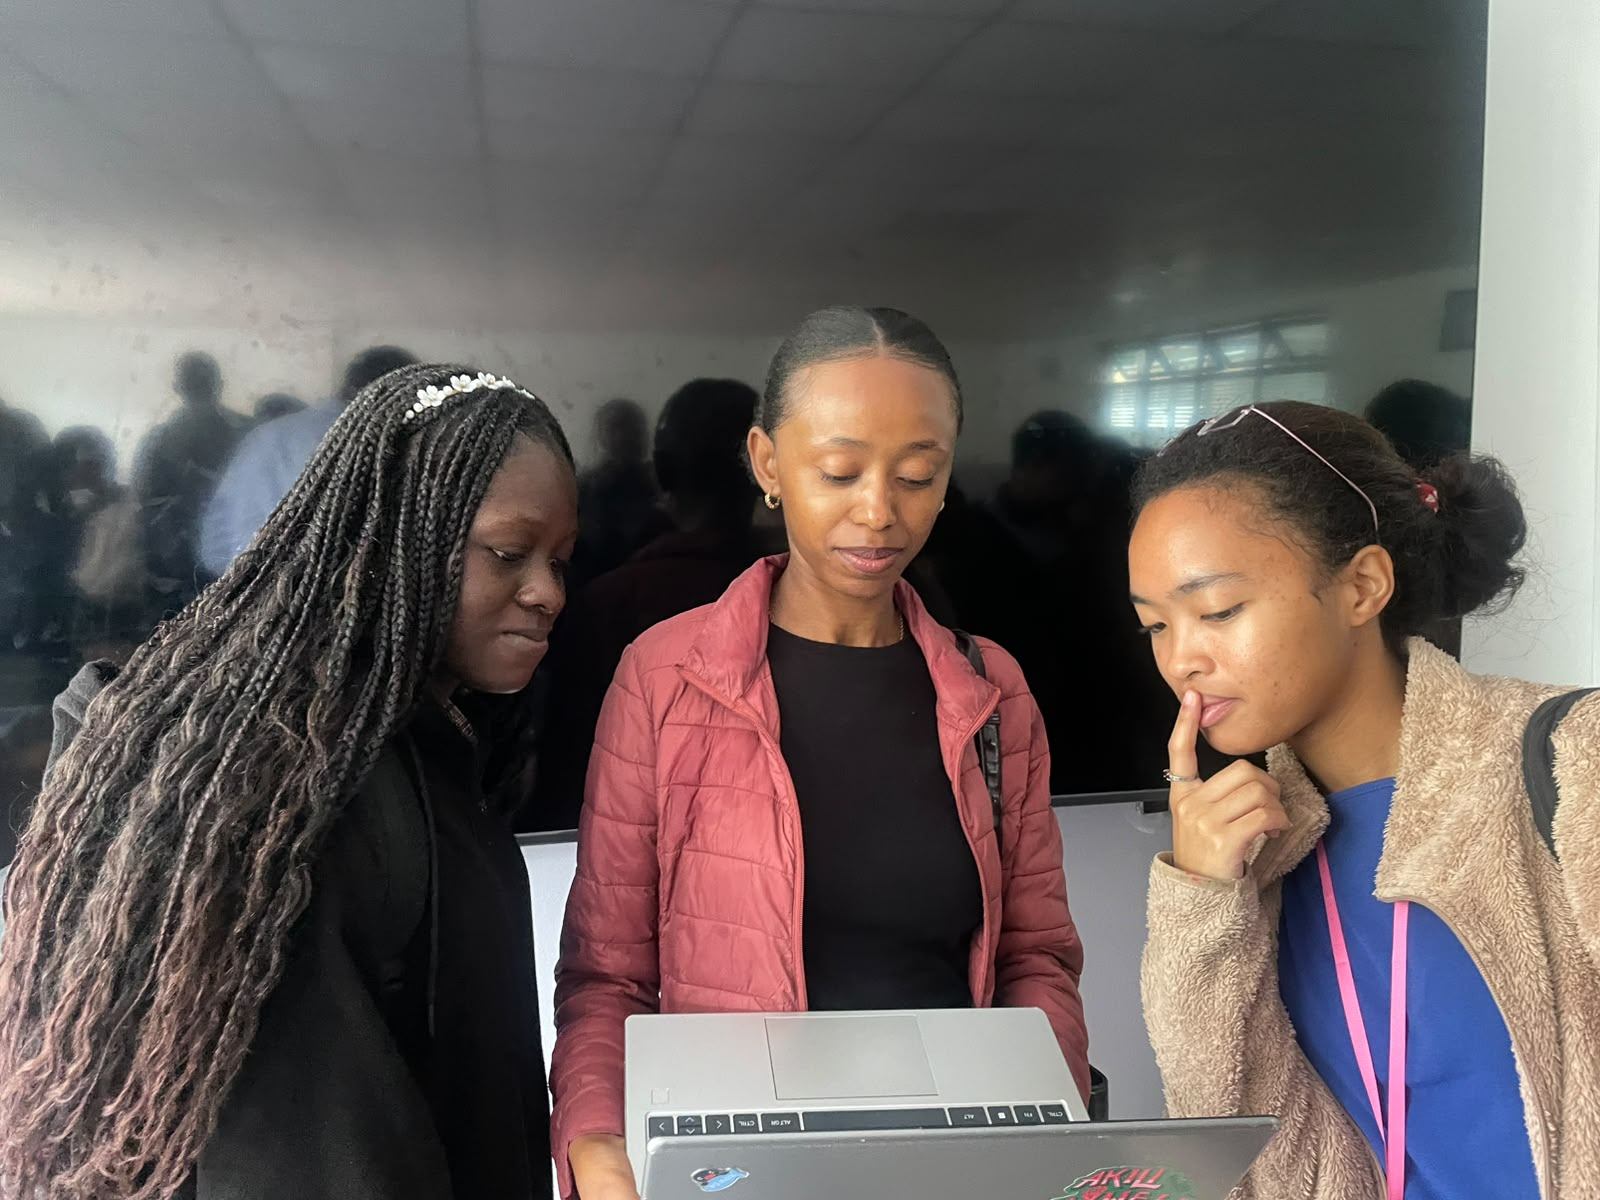